/tmp/ipykernel_11062/3237714667.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


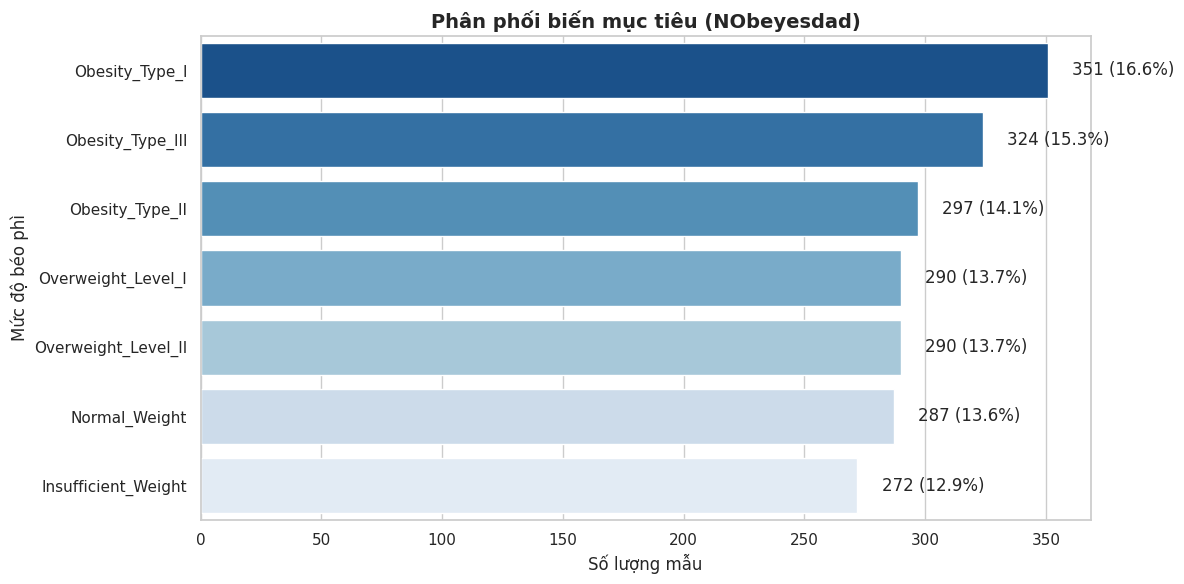

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')
plt.figure(figsize=(12, 6))
sns.set_theme(style='whitegrid')

ax = sns.countplot(
    data=df,
    y='NObeyesdad',
    order=df['NObeyesdad'].value_counts().index,
    palette='Blues_r',
)

total = len(df)
for p in ax.patches:
  count = int(p.get_width())
  percentage = f'{100 * count / total:.1f}%'
  ax.annotate(
      f'{count} ({percentage})',
      (p.get_width() + 10, p.get_y() + p.get_height() / 2),
      ha='left',
      va='center',
  )

plt.title('Phân phối biến mục tiêu (NObeyesdad)', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng mẫu')
plt.ylabel('Mức độ béo phì')
plt.tight_layout()
plt.show()

In [56]:
import pandas as pd
import numpy as np

df = pd.read_csv('data.csv')
df_clean = df.copy()

#bỏ trùng lặp
df_clean = df_clean.drop_duplicates()

#làm tròn các số thập phân
discrete_cols = ['Age', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
for col in discrete_cols:
    df_clean[col] = df_clean[col].round()

#chuyển chữ sang số
#(có /ko)tiền sử gia đình, có ăn nhiều đồ giàu calo, hút thuốc, theo dõi calo bữa ăn
binary_cols = ['family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC']
for col in binary_cols:
    df_clean[col] = df_clean[col].map({'yes': 1, 'no': 0})
#giới tính chuyển về 0,1
df_clean['Gender'] = df_clean['Gender'].map({'Female': 0, 'Male': 1})
#chuyển các dữ liệu có thứ tự mức độ
ordinal_map = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
df_clean['CAEC'] = df_clean['CAEC'].map(ordinal_map)
df_clean['CALC'] = df_clean['CALC'].map(ordinal_map)
#chuyển các dữ liệu không có thứ tự mức độ
df_clean = pd.get_dummies(df_clean, columns=['MTRANS'], drop_first=True, dtype=int)

print(df_clean.info())

df_clean.head(10)


<class 'pandas.core.frame.DataFrame'>
Index: 2087 entries, 0 to 2110
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2087 non-null   int64  
 1   Age                             2087 non-null   float64
 2   Height                          2087 non-null   float64
 3   Weight                          2087 non-null   float64
 4   family_history_with_overweight  2087 non-null   int64  
 5   FAVC                            2087 non-null   int64  
 6   FCVC                            2087 non-null   float64
 7   NCP                             2087 non-null   float64
 8   CAEC                            2087 non-null   int64  
 9   SMOKE                           2087 non-null   int64  
 10  CH2O                            2087 non-null   float64
 11  SCC                             2087 non-null   int64  
 12  FAF                             2087 no

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,NObeyesdad,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,0,21.0,1.62,64.0,1,0,2.0,3.0,1,0,2.0,0,0.0,1.0,0,Normal_Weight,0,0,1,0
1,0,21.0,1.52,56.0,1,0,3.0,3.0,1,1,3.0,1,3.0,0.0,1,Normal_Weight,0,0,1,0
2,1,23.0,1.80,77.0,1,0,2.0,3.0,1,0,2.0,0,2.0,1.0,2,Normal_Weight,0,0,1,0
3,1,27.0,1.80,87.0,0,0,3.0,3.0,1,0,2.0,0,2.0,0.0,2,Overweight_Level_I,0,0,0,1
4,1,22.0,1.78,89.8,0,0,2.0,1.0,1,0,2.0,0,0.0,0.0,1,Overweight_Level_II,0,0,1,0
5,1,29.0,1.62,53.0,0,1,2.0,3.0,1,0,2.0,0,0.0,0.0,1,Normal_Weight,0,0,0,0
6,0,23.0,1.50,55.0,1,1,3.0,3.0,1,0,2.0,0,1.0,0.0,1,Normal_Weight,0,1,0,0
7,1,22.0,1.64,53.0,0,0,2.0,3.0,1,0,2.0,0,3.0,0.0,1,Normal_Weight,0,0,1,0
8,1,24.0,1.78,64.0,1,1,3.0,3.0,1,0,2.0,0,1.0,1.0,2,Normal_Weight,0,0,1,0
9,1,22.0,1.72,68.0,1,1,2.0,3.0,1,0,2.0,0,1.0,1.0,0,Normal_Weight,0,0,1,0


In [57]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_recall_fscore_support,recall_score
import matplotlib.pyplot as plt
import seaborn as sns

X = df_clean.drop('NObeyesdad',axis=1)
y = df_clean['NObeyesdad']
le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded, test_size=0.30, random_state=42, stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

best_val_recall_dt = 0
best_params_dt = {}
for depth in range(1,16):
  for split in range(2,21):
    model = DecisionTreeClassifier(
          max_depth=depth,
          min_samples_split=split,
          random_state=42,
      )
    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)
    val_recall = recall_score(y_val, y_val_pred, average='macro', zero_division=0)
    if val_recall > best_val_recall_dt:
        best_val_recall_dt = val_recall
        best_params_dt = {
            'max_depth': depth,
            'min_samples_split': split,

        }


print(f"\n--- Độ chính xác(recall) trên tập Validation dùng dt: {best_val_recall_dt * 100:.2f}% ---")
model_dt = DecisionTreeClassifier(**best_params_dt, random_state=42)
model_dt.fit(X_train, y_train)

y_test_pred_dt = model_dt.predict(X_test)
test_recall_dt = recall_score(y_test, y_test_pred_dt, average='macro', zero_division=0)
print(
    f'\n--- Độ chính xác(recall) cuối cùng trên tập TEST dùng dt: {test_recall_dt * 100:.2f}% ---'
)

best_val_recall_rf = 0
best_params_rf = {}

for n_est in [50, 100, 150]:
  for depth in [5, 10, 15]:
    model = RandomForestClassifier(
        n_estimators=n_est, max_depth=depth, random_state=42
    )
    model.fit(X_train, y_train)

    y_val_pred = model.predict(X_val)
    val_recall = recall_score(
        y_val, y_val_pred, average='macro', zero_division=0
    )

    if val_recall > best_val_recall_rf:
      best_val_recall_rf = val_recall
      best_params_rf = {'n_estimators': n_est, 'max_depth': depth}
print(f"\n--- Độ chính xác(recall) trên tập Validation dùng rf: {best_val_recall_rf * 100:.2f}% ---")
model_rf = RandomForestClassifier(**best_params_rf, random_state=42)
model_rf.fit(X_train, y_train)

y_test_pred_rf = model_rf.predict(X_test)
test_recall_rf = recall_score(y_test, y_test_pred_rf, average='macro', zero_division=0)
print(
    f'\n--- Độ chính xác(recall) cuối cùng trên tập TEST dùng rf: {test_recall_rf * 100:.2f}% ---'
)

def evaluate_all_metrics(y_true, y_pred):
  acc = accuracy_score(y_true, y_pred)
  prec, rec, f1, _ = precision_recall_fscore_support(
      y_true, y_pred, average='macro', zero_division=0
  )
  return {
      'Accuracy': round(acc * 100, 2),
      'Precision (Macro)': round(prec * 100, 2),
      'Recall (Macro)': round(rec * 100, 2),
      'F1-Score (Macro)': round(f1 * 100, 2),
  }



metrics_dt = evaluate_all_metrics(y_test, y_test_pred_dt)
metrics_rf = evaluate_all_metrics(y_test, y_test_pred_rf)

df_comparison = pd.DataFrame(
    [metrics_dt, metrics_rf], index=['Decision Tree', 'Random Forest']
)

print('=== BẢNG SO SÁNH 4 CHỈ SỐ ĐÁNH GIÁ TRÊN TẬP TEST (%) ===')
print(df_comparison)


--- Độ chính xác(recall) trên tập Validation dùng dt: 93.46% ---

--- Độ chính xác(recall) cuối cùng trên tập TEST dùng dt: 94.00% ---

--- Độ chính xác(recall) trên tập Validation dùng rf: 94.35% ---

--- Độ chính xác(recall) cuối cùng trên tập TEST dùng rf: 93.94% ---
=== BẢNG SO SÁNH 4 CHỈ SỐ ĐÁNH GIÁ TRÊN TẬP TEST (%) ===
               Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)
Decision Tree     94.27              93.96           94.00             93.97
Random Forest     94.27              93.97           93.94             93.95
